# FraudShield AI
## Intelligent Credit Card Fraud Detection System

### Project Objective
To develop a Machine Learning system that identifies
fraudulent and legitimate credit card transactions.

### Dataset
European Credit Card Fraud Detection Dataset
from KAGGLE
### Machine Learning Algorithms
- Random Forest
- XGBoost

### Evaluation Metrics
- Precision
- Recall
- F1-Score
- ROC-AUC
- PR-AUC


In [1]:
##IMPORTING LIBRARIES
# Data handling
import pandas as pd
import numpy as np
# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df=pd.read_csv("../Data/creditcard.csv")
print("Dataset Loaded Successfully!")
print("Dataset Shape:",df.shape)
print("\n First Five Transactions")
df.head()

Dataset Loaded Successfully!
Dataset Shape: (284807, 31)

 First Five Transactions


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
#display all columns names
print("\n Columns Names:", df.columns.tolist())
#Display information
print("\n Dataset Information:", df.info())



 Columns Names: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 no

In [5]:
#Missing values in cloumns
print("Missing values:", df.isnull().sum())
#Class Distribution
print(df["Class"].value_counts())
#Class Distribution in Percentagr
print(df["Class"].value_counts(normalize=True) * 100)

Missing values: Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


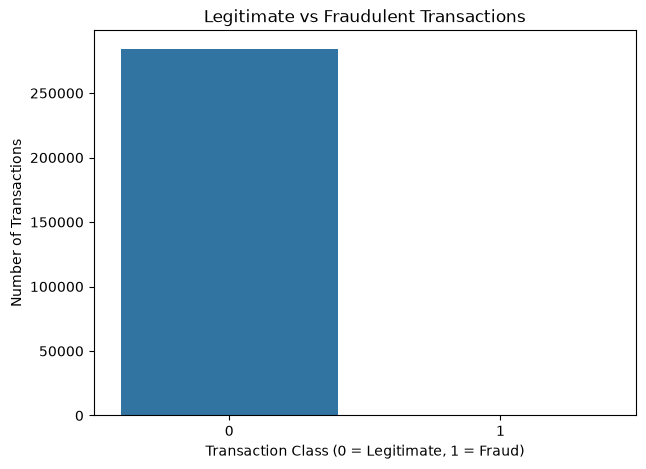

In [6]:
# Visualize transaction class distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Class")
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

In [7]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 1081


In [8]:
# Select all duplicate rows
duplicates = df[df.duplicated(keep=False)]
# Count duplicate rows by transaction class
print(duplicates["Class"].value_counts())

Class
0    1822
1      32
Name: count, dtype: int64


In [9]:
# Statistical summary of transaction amounts
print(df["Amount"].describe())

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64


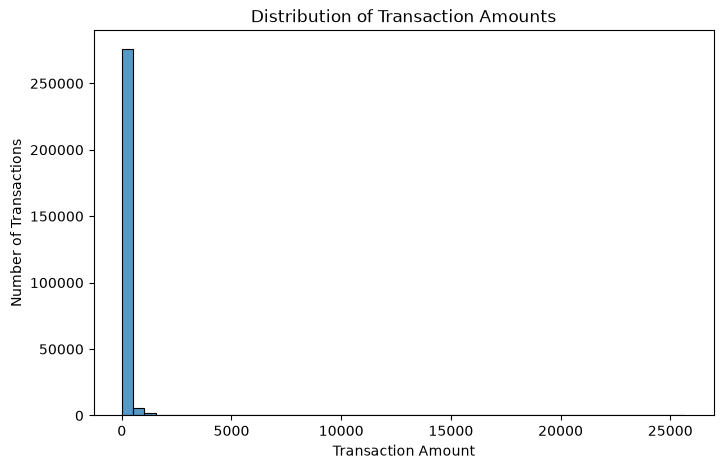

In [10]:
# Create a histogram of transaction amounts
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Amount", bins=50)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.show()

In [11]:
# Compare transaction amounts by class
print("Average Transaction Amount:")
print(df.groupby("Class")["Amount"].mean())
print("\nMedian Transaction Amount:")
print(df.groupby("Class")["Amount"].median())

Average Transaction Amount:
Class
0     88.291022
1    122.211321
Name: Amount, dtype: float64

Median Transaction Amount:
Class
0    22.00
1     9.25
Name: Amount, dtype: float64


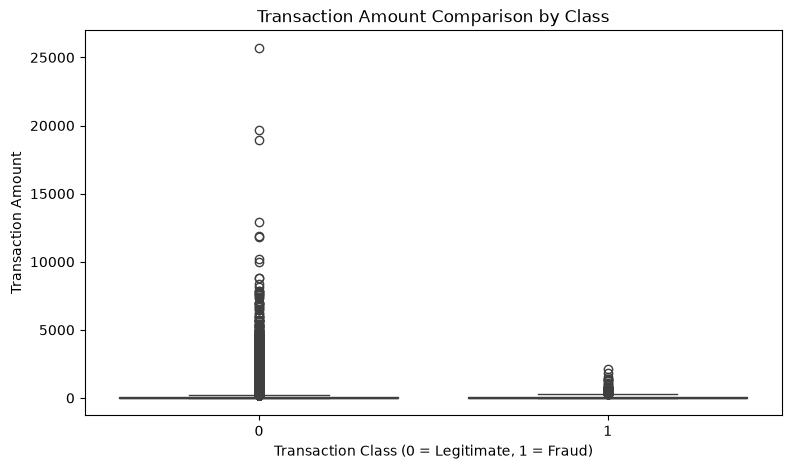

In [12]:
# Compare transaction amount distributions
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Class", y="Amount")
plt.title("Transaction Amount Comparison by Class")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.show()

In [13]:
# Statistical summary of transaction time
print(df["Time"].describe())

count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64


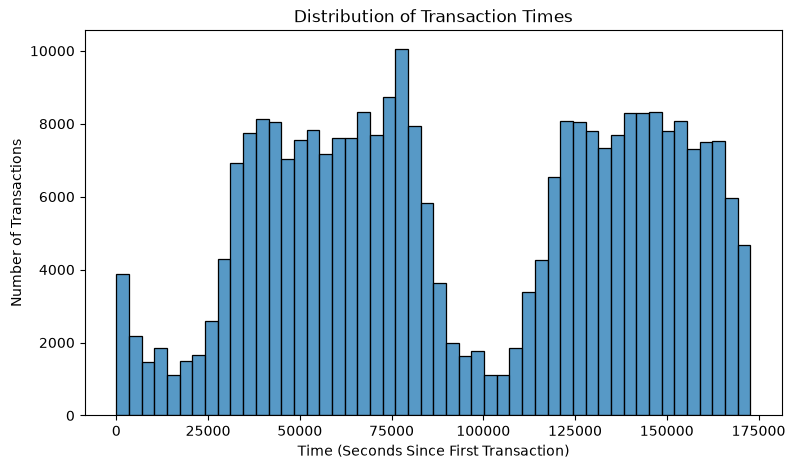

In [14]:
# Visualize transaction time distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="Time", bins=50)
plt.title("Distribution of Transaction Times")
plt.xlabel("Time (Seconds Since First Transaction)")
plt.ylabel("Number of Transactions")

plt.show()

In [15]:
# Compare average transaction time by class

print("Average Transaction Time:")
print(df.groupby("Class")["Time"].mean())

print("\nMedian Transaction Time:")
print(df.groupby("Class")["Time"].median())

Average Transaction Time:
Class
0    94838.202258
1    80746.806911
Name: Time, dtype: float64

Median Transaction Time:
Class
0    84711.0
1    75568.5
Name: Time, dtype: float64


In [16]:
# Calculate correlation between dataset features

correlation = df.corr()

# Display correlation with target column
print(correlation["Class"].sort_values(ascending=False))

Class     1.000000
V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
V26       0.004455
V25       0.003308
V22       0.000805
V23      -0.002685
V15      -0.004223
V13      -0.004570
V24      -0.007221
Time     -0.012323
V6       -0.043643
V5       -0.094974
V9       -0.097733
V1       -0.101347
V18      -0.111485
V7       -0.187257
V3       -0.192961
V16      -0.196539
V10      -0.216883
V12      -0.260593
V14      -0.302544
V17      -0.326481
Name: Class, dtype: float64


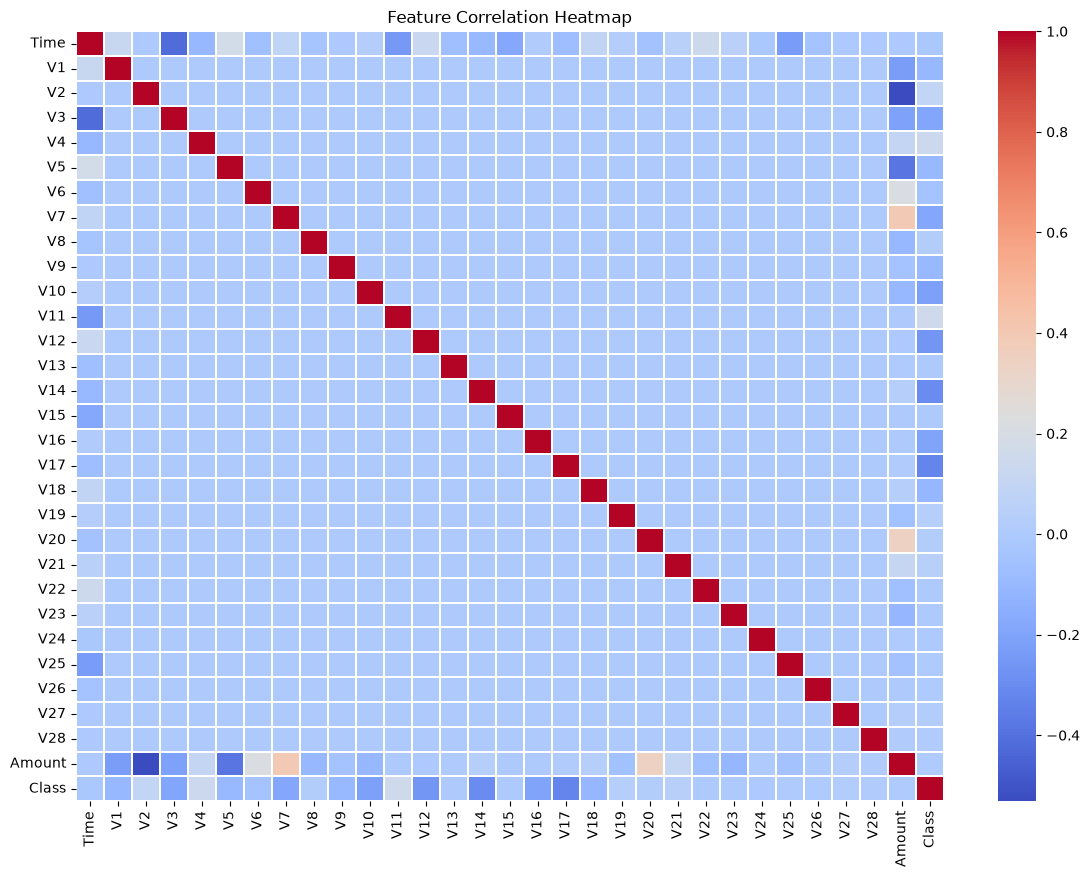

In [17]:
# Create correlation heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    linewidths=0.3
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [18]:
##Seperate Target and features
X = df.drop("Class", axis=1)
y = df["Class"]
# Check their shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (284807, 30)
Target Shape: (284807,)


*Split the Dataset*

In [19]:
# Import train_test_split
from sklearn.model_selection import train_test_split

In [20]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# Display dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (227845, 30)
Testing Features: (56962, 30)
Training Target: (227845,)
Testing Target: (56962,)


In [21]:
# Check class distribution in training data

print("Training Class Distribution:")
print(y_train.value_counts())

# Check class distribution in testing data

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Class Distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing Class Distribution:
Class
0    56864
1       98
Name: count, dtype: int64


*Importing model libraries*

In [22]:
# Import Random Forest
from sklearn.ensemble import RandomForestClassifier

# Import XGBoost
from xgboost import XGBClassifier

# Import evaluation metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [23]:
# Create Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

*Train Random Forest Model*

In [24]:
# Train Random Forest model
rf_model.fit(X_train, y_train)
print("Random Forest Training Completed!")

Random Forest Training Completed!


In [25]:
# Predict transaction classes using Random Forest

rf_predictions = rf_model.predict(X_test)

# Display first 10 predictions
print("First 10 Predictions:")
print(rf_predictions[:10])

First 10 Predictions:
[0 0 0 0 0 0 0 0 0 0]


In [26]:
# Generate classification report

print(classification_report(y_test, rf_predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.91      0.79      0.84        98

    accuracy                           1.00     56962
   macro avg       0.95      0.89      0.92     56962
weighted avg       1.00      1.00      1.00     56962



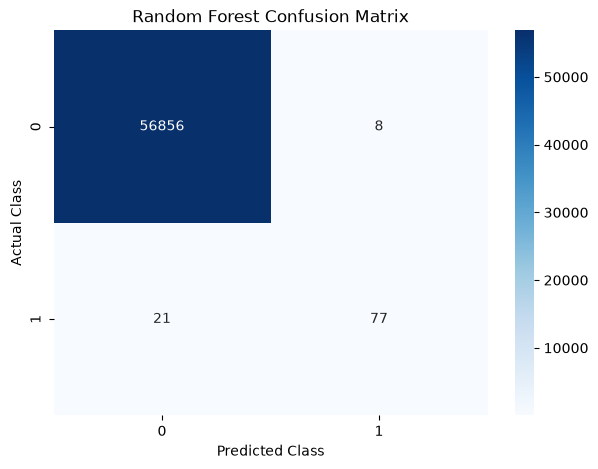

In [27]:
# Generate confusion matrix
rf_cm = confusion_matrix(y_test, rf_predictions)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [28]:
# Get fraud probabilities
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
rf_roc_auc = roc_auc_score(y_test, rf_probabilities)

# Calculate PR-AUC
rf_pr_auc = average_precision_score(y_test, rf_probabilities)

print("Random Forest ROC-AUC:", rf_roc_auc)
print("Random Forest PR-AUC:", rf_pr_auc)

Random Forest ROC-AUC: 0.9573108734912085
Random Forest PR-AUC: 0.862939836265611


*Now prepare for XG BOOST*

In [29]:
# Count legitimate transactions
negative_count = (y_train == 0).sum()

# Count fraudulent transactions
positive_count = (y_train == 1).sum()

# Calculate the imbalance ratio
scale_weight = negative_count / positive_count

print("Legitimate Transactions:", negative_count)
print("Fraud Transactions:", positive_count)
print("Scale Positive Weight:", scale_weight)    ##WE use scale_pos_Weight parameter so XG BOOST gives more importance to fraudlent transactions

Legitimate Transactions: 227451
Fraud Transactions: 394
Scale Positive Weight: 577.2868020304569


In [30]:
##configure XG BOSST
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

*NOWWWW Training of Second Model*

In [31]:
# Train the XGBoost model
xgb_model.fit(X_train, y_train)
print("XGBoost Training Completed!")

XGBoost Training Completed!


In [32]:
# Predict transaction classes
xgb_predictions = xgb_model.predict(X_test)
# Display the first 10 predictions
print(xgb_predictions[:10])

[0 0 0 0 0 0 0 0 0 0]


In [33]:
print(classification_report(y_test, xgb_predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.59      0.86      0.70        98

    accuracy                           1.00     56962
   macro avg       0.80      0.93      0.85     56962
weighted avg       1.00      1.00      1.00     56962



*XG BOOST confusion matrix*

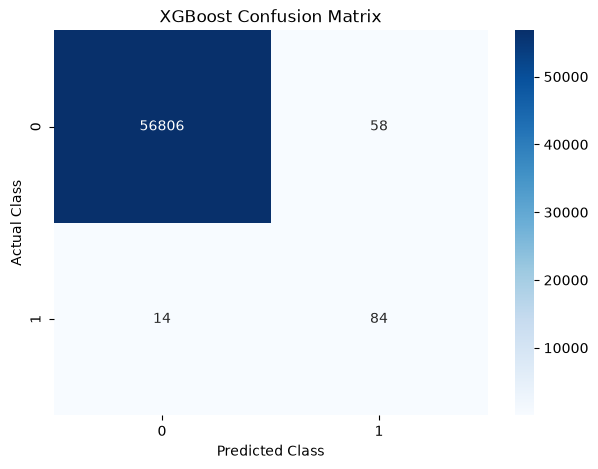

In [34]:
xgb_cm = confusion_matrix(y_test, xgb_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [35]:
# Get fraud probabilities
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]
# Calculate ROC-AUC
xgb_roc_auc = roc_auc_score(y_test, xgb_probabilities)
# Calculate PR-AUC (Average Precision)
xgb_pr_auc = average_precision_score(y_test, xgb_probabilities)
print("XGBoost ROC-AUC:", xgb_roc_auc)
print("XGBoost PR-AUC:", xgb_pr_auc)

XGBoost ROC-AUC: 0.9778282303354657
XGBoost PR-AUC: 0.8552211748179931


*Comparison Table*

In [36]:
comparison = pd.DataFrame({
    "Random Forest": [0.91, 0.79, 0.84, rf_roc_auc, rf_pr_auc],
    "XGBoost": [0.59, 0.86, 0.70, xgb_roc_auc, xgb_pr_auc]
}, index=["Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"])

comparison

,Random Forest,XGBoost
Precision,0.910000,0.590000
Recall,0.790000,0.860000
F1-Score,0.840000,0.700000
ROC-AUC,0.957311,0.977828
PR-AUC,0.862940,0.855221


In [37]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)
print("Model Training Data:", X_fit.shape)
print("Validation Data:", X_val.shape)
print("Training Fraud Cases:", (y_fit == 1).sum())
print("Validation Fraud Cases:", (y_val == 1).sum())

Model Training Data: (182276, 30)
Validation Data: (45569, 30)
Training Fraud Cases: 315
Validation Fraud Cases: 79


*Temporary training of Random Forest For Validation*

In [38]:
rf_tune = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_tune.fit(X_fit, y_fit)

print("Random Forest Validation Model Trained!")

Random Forest Validation Model Trained!


In [39]:
rf_val_probabilities = rf_tune.predict_proba(X_val)[:, 1]

print("First 10 Fraud Probabilities:")
print(rf_val_probabilities[:10])

First 10 Fraud Probabilities:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [40]:
print("Minimum Probability:", rf_val_probabilities.min())
print("Maximum Probability:", rf_val_probabilities.max())
print("Average Probability:", rf_val_probabilities.mean())

print("\nUnique Probability Values:")
print(len(np.unique(rf_val_probabilities)))

Minimum Probability: 0.0
Maximum Probability: 1.0
Average Probability: 0.001996313283153021

Unique Probability Values:
58


In [41]:
##Setting the thresholds
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:

    predictions = (rf_val_probabilities >= threshold).astype(int)

    precision = precision_score(y_val, predictions, zero_division=0)
    recall = recall_score(y_val, predictions, zero_division=0)
    f1 = f1_score(y_val, predictions, zero_division=0)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision, 3))
    print("Recall:", round(recall, 3))
    print("F1-Score:", round(f1, 3))


Threshold: 0.1
Precision: 0.699
Recall: 0.823
F1-Score: 0.756

Threshold: 0.2
Precision: 0.808
Recall: 0.797
F1-Score: 0.803

Threshold: 0.3
Precision: 0.827
Recall: 0.785
F1-Score: 0.805

Threshold: 0.4
Precision: 0.899
Recall: 0.785
F1-Score: 0.838

Threshold: 0.5
Precision: 0.908
Recall: 0.747
F1-Score: 0.819


*Temporary XG BOOST training for Validation*

In [42]:
xgb_tune = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y_fit == 0).sum() / (y_fit == 1).sum(),
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

xgb_tune.fit(X_fit, y_fit)

print("XGBoost Validation Model Trained!")

XGBoost Validation Model Trained!


In [43]:
# Get fraud probabilities from XGBoost
xgb_val_probabilities = xgb_tune.predict_proba(X_val)[:, 1]

print("First 10 Fraud Probabilities:")
print(xgb_val_probabilities[:10])

First 10 Fraud Probabilities:
[7.8267505e-04 1.6313485e-03 1.5345804e-04 7.0080096e-05 5.3525763e-04
 2.1563728e-04 2.4362278e-04 2.4256839e-03 2.4066942e-03 2.3168041e-03]


In [44]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:

    predictions = (xgb_val_probabilities >= threshold).astype(int)

    precision = precision_score(y_val, predictions, zero_division=0)
    recall = recall_score(y_val, predictions, zero_division=0)
    f1 = f1_score(y_val, predictions, zero_division=0)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision, 3))
    print("Recall:", round(recall, 3))
    print("F1-Score:", round(f1, 3))


Threshold: 0.1
Precision: 0.316
Recall: 0.835
F1-Score: 0.458

Threshold: 0.2
Precision: 0.496
Recall: 0.81
F1-Score: 0.615

Threshold: 0.3
Precision: 0.627
Recall: 0.81
F1-Score: 0.707

Threshold: 0.4
Precision: 0.696
Recall: 0.81
F1-Score: 0.749

Threshold: 0.5
Precision: 0.741
Recall: 0.797
F1-Score: 0.768


In [45]:
from sklearn.metrics import precision_recall_curve

rf_precision, rf_recall, rf_thresholds = precision_recall_curve(
    y_val,
    rf_val_probabilities
)

rf_f1_scores = (
    2 * rf_precision[:-1] * rf_recall[:-1]
    / (rf_precision[:-1] + rf_recall[:-1] + 1e-10)
)

best_rf_index = np.argmax(rf_f1_scores)

best_rf_threshold = rf_thresholds[best_rf_index]

print("Best RF Threshold:", best_rf_threshold)
print("Best RF Precision:", rf_precision[best_rf_index])
print("Best RF Recall:", rf_recall[best_rf_index])
print("Best RF F1-Score:", rf_f1_scores[best_rf_index])

Best RF Threshold: 0.41
Best RF Precision: 0.8985507246376812
Best RF Recall: 0.7848101265822784
Best RF F1-Score: 0.8378378377880661


In [46]:
xgb_precision, xgb_recall, xgb_thresholds = precision_recall_curve(
    y_val,
    xgb_val_probabilities
)

xgb_f1_scores = (
    2 * xgb_precision[:-1] * xgb_recall[:-1]
    / (xgb_precision[:-1] + xgb_recall[:-1] + 1e-10)
)

best_xgb_index = np.argmax(xgb_f1_scores)

best_xgb_threshold = xgb_thresholds[best_xgb_index]

print("Best XGBoost Threshold:", best_xgb_threshold)
print("Best XGBoost Precision:", xgb_precision[best_xgb_index])
print("Best XGBoost Recall:", xgb_recall[best_xgb_index])
print("Best XGBoost F1-Score:", xgb_f1_scores[best_xgb_index])

Best XGBoost Threshold: 0.954206
Best XGBoost Precision: 0.9117647058823529
Best XGBoost Recall: 0.7848101265822784
Best XGBoost F1-Score: 0.8435374149162662


In [47]:
# Generate test probabilities
rf_test_probabilities = rf_tune.predict_proba(X_test)[:, 1]
xgb_test_probabilities = xgb_tune.predict_proba(X_test)[:, 1]

# Apply the selected thresholds
rf_test_predictions = (rf_test_probabilities >= best_rf_threshold).astype(int)
xgb_test_predictions = (xgb_test_probabilities >= best_xgb_threshold).astype(int)

print("Test predictions generated successfully!")

Test predictions generated successfully!


In [48]:
## comparison between both models
# Random Forest test performance
rf_test_precision = precision_score(y_test, rf_test_predictions)
rf_test_recall = recall_score(y_test, rf_test_predictions)
rf_test_f1 = f1_score(y_test, rf_test_predictions)

# XGBoost test performance
xgb_test_precision = precision_score(y_test, xgb_test_predictions)
xgb_test_recall = recall_score(y_test, xgb_test_predictions)
xgb_test_f1 = f1_score(y_test, xgb_test_predictions)

print("RANDOM FOREST")
print("Precision:", round(rf_test_precision, 4))
print("Recall:", round(rf_test_recall, 4))
print("F1-Score:", round(rf_test_f1, 4))

print("\nXGBOOST")
print("Precision:", round(xgb_test_precision, 4))
print("Recall:", round(xgb_test_recall, 4))
print("F1-Score:", round(xgb_test_f1, 4))

RANDOM FOREST
Precision: 0.8913
Recall: 0.8367
F1-Score: 0.8632

XGBOOST
Precision: 0.8791
Recall: 0.8163
F1-Score: 0.8466


In [49]:
##Final confusion matrix
# Random Forest confusion matrix
rf_final_cm = confusion_matrix(y_test, rf_test_predictions)

# XGBoost confusion matrix
xgb_final_cm = confusion_matrix(y_test, xgb_test_predictions)

print("Random Forest Confusion Matrix:")
print(rf_final_cm)

print("\nXGBoost Confusion Matrix:")
print(xgb_final_cm)

Random Forest Confusion Matrix:
[[56854    10]
 [   16    82]]

XGBoost Confusion Matrix:
[[56853    11]
 [   18    80]]


In [50]:
##TRAINING OF OUR SELECTED MODEL
final_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

print("Final Random Forest Model Trained Successfully!")

Final Random Forest Model Trained Successfully!


In [51]:
final_threshold = best_rf_threshold

print("Selected Fraud Threshold:", final_threshold)

Selected Fraud Threshold: 0.41


In [52]:
import joblib
import os

In [53]:
# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save trained Random Forest model
joblib.dump(final_model, "../models/fraudshield_model.pkl")

# Save selected threshold
joblib.dump(final_threshold, "../models/fraud_threshold.pkl")

print("Model and threshold saved successfully!")

Model and threshold saved successfully!


In [54]:
# Check whether saved files exist
print("Model exists:", os.path.exists("../models/fraudshield_model.pkl"))
print("Threshold exists:", os.path.exists("../models/fraud_threshold.pkl"))

# Load saved model and threshold
loaded_model = joblib.load("../models/fraudshield_model.pkl")
loaded_threshold = joblib.load("../models/fraud_threshold.pkl")

print("\nModel loaded successfully!")
print("Selected threshold:", loaded_threshold)
print("Number of input features:", loaded_model.n_features_in_)

Model exists: True
Threshold exists: True

Model loaded successfully!
Selected threshold: 0.41
Number of input features: 30


In [55]:
# Save the exact feature order used during training
joblib.dump(X_train.columns.tolist(), "../models/feature_columns.pkl")

print("Feature names saved successfully!")
print("Total features:", len(X_train.columns))
print("First 5 features:", X_train.columns[:5].tolist())
print("Last 5 features:", X_train.columns[-5:].tolist())

Feature names saved successfully!
Total features: 30
First 5 features: ['Time', 'V1', 'V2', 'V3', 'V4']
Last 5 features: ['V25', 'V26', 'V27', 'V28', 'Amount']


In [56]:
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Load dataset
data = pd.read_csv("../Data/creditcard.csv")

# Load saved model and threshold
model = joblib.load("../models/fraudshield_model.pkl")
threshold = joblib.load("../models/fraud_threshold.pkl")
feature_columns = joblib.load("../models/feature_columns.pkl")

# Separate features and actual labels
X = data[feature_columns]
y = data["Class"]

# Recreate the original test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Get fraud probabilities
probabilities = model.predict_proba(X_test)[:, 1]

# Apply saved threshold
predictions = (probabilities >= threshold).astype(int)

# Evaluation
print("FRAUDSHIELD AI - MODEL EVALUATION")
print("----------------------------------")

print("Threshold:", threshold)
print("Test transactions:", len(X_test))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Legitimate", "Fraud"]
))

print("Precision:", precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))
print("F1-Score:", f1_score(y_test, predictions))

FRAUDSHIELD AI - MODEL EVALUATION
----------------------------------
Threshold: 0.41
Test transactions: 56962

Confusion Matrix:
[[56853    11]
 [   18    80]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.88      0.82      0.85        98

    accuracy                           1.00     56962
   macro avg       0.94      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Precision: 0.8791208791208791
Recall: 0.8163265306122449
F1-Score: 0.8465608465608465


In [ ]:
import pandas as pd

df = pd.read_csv("data/creditcard.csv")

sample = df.sample(n=1000, random_state=42)

sample.drop(columns=["Class"], errors="ignore").to_csv(
    "data/test_transactions.csv",
    index=False
)

print("Test CSV created successfully!")